# Lab 04 — Bài toán 1: Hồi quy tuyến tính đa biến (Housing)

**Chạy trên VS Code:** Mở thư mục dự án, chọn Python kernel của `ml_lab_env`, bấm **Run All**. Notebook đọc dữ liệu theo đường dẫn tương đối từ `notebooks/`.

Quy trình: đọc dữ liệu → mã hóa → chia 80/20 → chuẩn hóa chỉ trên Train → LinearRegression → MAE/RMSE/R² → biểu đồ & phân tích hệ số.

## 1. Import và quan sát dữ liệu

In [1]:
%pip install scikit-learn
from pathlib import Path
%pip install pandas
%pip install matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA = Path('../data/raw/Housing.csv')
df = pd.read_csv(DATA)
print('Kích thước dữ liệu:', df.shape)
print('Giá trị thiếu:', df.isna().sum().sum())
display(df.head())

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Kích thước dữ liệu: (545, 13)
Giá trị thiếu: 0


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 2. Tách mục tiêu và chuyển đổi biến định tính

`yes/no` → 1/0, `furnishingstatus` → One-Hot (bỏ nhóm tham chiếu để tránh bẫy biến giả).

In [3]:
X_raw = df.drop(columns=['price']).copy()
y = df['price']
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    X_raw[col] = X_raw[col].map({'yes': 1, 'no': 0})
X_encoded = pd.get_dummies(X_raw, columns=['furnishingstatus'], drop_first=True, dtype=int)
assert not X_encoded.isna().any().any()
print('Số đặc trưng sau mã hóa:', X_encoded.shape[1])
display(X_encoded.head())

Số đặc trưng sau mã hóa: 13


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,7420,4,1,2,1,1,1,0,1,2,0,0,0


## 3. Chia 80% Train – 20% Test

`random_state=42` đảm bảo kết quả có thể tái lập.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (436, 13) Test: (109, 13)


## 4. Chuẩn hóa an toàn (không Data Leakage)

**Chỉ** `fit_transform` trên Train; dùng `transform` trên Test.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Trung bình area trên tập Train:', X_train['area'].mean())
print('scaler.mean_[area]:', scaler.mean_[X_train.columns.get_loc('area')])

Trung bình area trên tập Train: 5154.144495412844
scaler.mean_[area]: 5154.144495412844


## 5. Huấn luyện và tính MAE, RMSE, R²

In [6]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f'MAE = {mae:,.2f}')
print(f'RMSE = {rmse:,.2f}')
print(f'R² = {r2:.4f}')

MAE = 970,043.40
RMSE = 1,324,506.96
R² = 0.6529


## 6. Biểu đồ phần dư và thực tế–dự đoán

Phần dư `y_test - y_pred` nên dao động quanh 0. Kiểm tra có hình phễu/đường cong hay không.

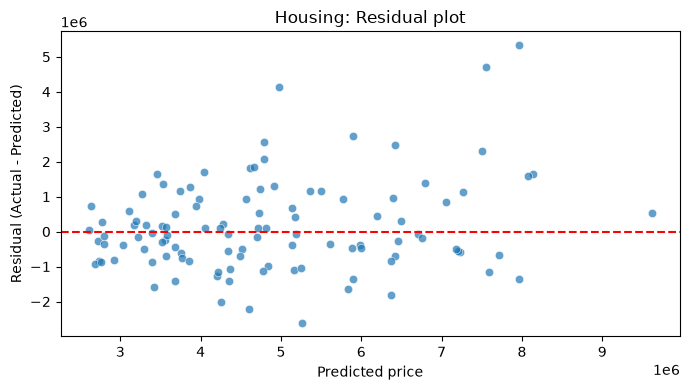

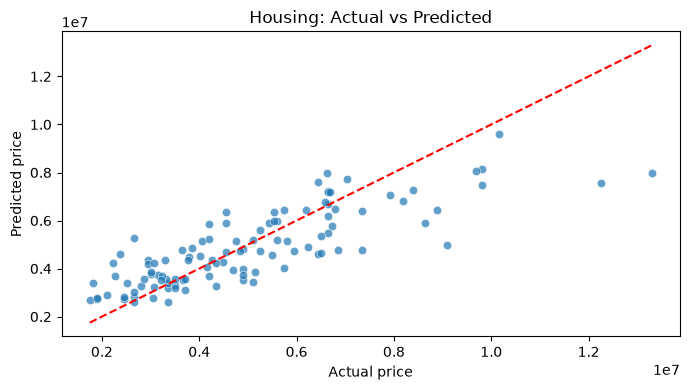

In [7]:
residuals = y_test.to_numpy() - y_pred
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(x=y_pred, y=residuals, ax=ax, alpha=.7)
ax.axhline(0, color='red', linestyle='--')
ax.set(xlabel='Predicted price', ylabel='Residual (Actual - Predicted)', title='Housing: Residual plot')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(x=y_test.to_numpy(), y=y_pred, ax=ax, alpha=.7)
lo = min(y_test.min(), y_pred.min()); hi = max(y_test.max(), y_pred.max())
ax.plot([lo, hi], [lo, hi], 'r--')
ax.set(xlabel='Actual price', ylabel='Predicted price', title='Housing: Actual vs Predicted')
plt.tight_layout()
plt.show()

## 7. Trọng số hồi quy

Các hệ số nằm trên **thang đặc trưng chuẩn hóa**, vì vậy độ lớn phản ánh mức thay đổi dự báo theo một độ lệch chuẩn (khi các biến khác cố định). Không suy diễn quan hệ nhân quả.

,He so (scaled)
bathrooms,521879.027748
area,519552.416340
airconditioning,365157.393851
stories,349251.438906
prefarea,266656.351993
parking,192005.953667
basement,187067.803214
hotwaterheating,149862.702991
mainroad,128498.628215
guestroom,88768.667686


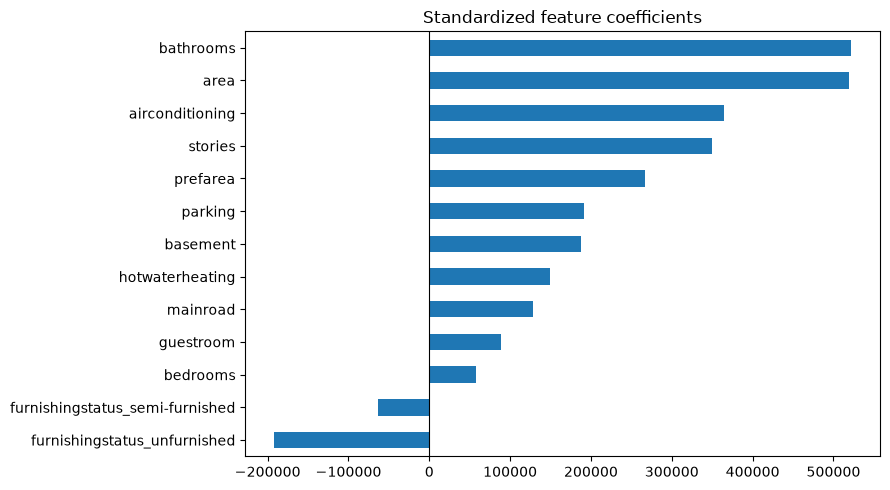

In [8]:
coef = pd.Series(model.coef_, index=X_encoded.columns).sort_values(ascending=False)
display(coef.to_frame('He so (scaled)'))
coef.sort_values().plot(kind='barh', figsize=(9, 5), title='Standardized feature coefficients')
plt.axvline(0, color='black', linewidth=.8)
plt.tight_layout()
plt.show()